In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

In [2]:
sim = AerSimulator()
shots = 100

In [3]:
qc_orig = QuantumCircuit(2, 2)
qc_orig.h(0)
qc_orig.cx(0, 1)
qc_orig.measure([0, 1], [0, 1])

In [4]:
qc_mod = QuantumCircuit(2, 2)
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)          # the single added gate
qc_mod.measure([0, 1], [0, 1])

Original circuit


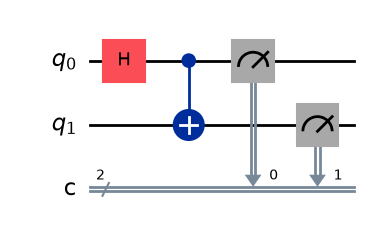

Modified circuit


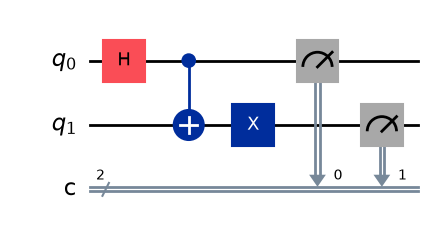

In [5]:
print("Original circuit")
display(qc_orig.draw('mpl'))
print("Modified circuit")
display(qc_mod.draw('mpl'))

In [6]:
counts_orig = sim.run(qc_orig, shots=shots).result().get_counts()
counts_mod = sim.run(qc_mod, shots=shots).result().get_counts()

print("Original:", counts_orig)
print("Modified:", counts_mod)

Original: {'11': 54, '00': 46}
Modified: {'01': 53, '10': 47}


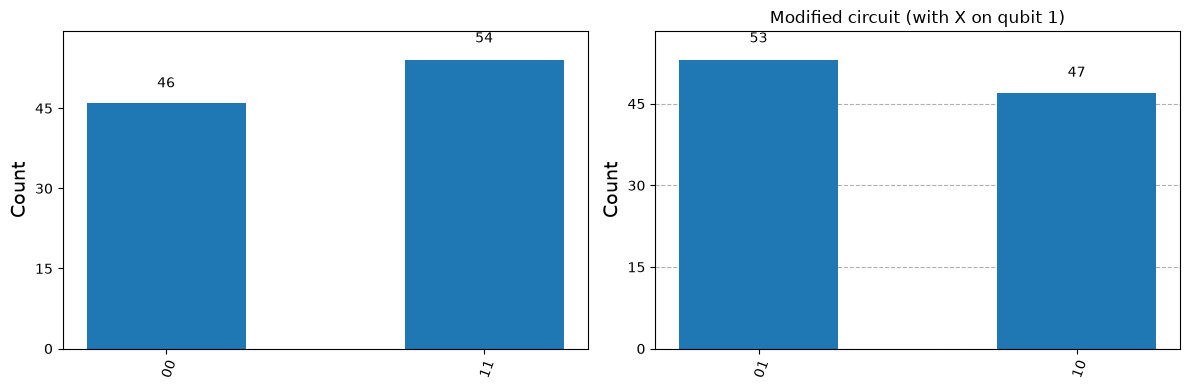

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_histogram(counts_orig, ax=axes[0], title="Original Bell circuit")
plot_histogram(counts_mod, ax=axes[1], title="Modified circuit (with X on qubit 1)")
plt.tight_layout()
plt.show()